# Fashion-MNIST: VAE y difusión

**Semilla aleatoria: `SEED = 42`.** Se fija en Python, NumPy y PyTorch. Para los tres VAE se reinicia antes de crear el modelo, de modo que todos parten de los mismos pesos.

El código usa PyTorch para los modelos y los cálculos. La reparametrización, la KL, la pérdida del VAE, el proceso forward, los calendarios, el muestreo ancestral y la guía sin clasificador están implementados directamente, sin `diffusers`, `torch.distributions.kl_divergence` ni muestreadores prefabricados.

**Uso de herramientas de IA.** Se utilizó IA como apoyo para revisar que las fórmulas se mostraran correctamente, comprobar la coherencia entre el enunciado, el código y los resultados, y señalar las partes incompletas del notebook. Prompt principal: *"Ayúdame a verificar que las fórmulas se vean bien, revisar que el código cumpla el enunciado y señalar lo que falte"* El mismo prompt se aplicó como revisión general a las Tasks 1-4. Funcionó porque enfocó la revisión en requisitos verificables y los resultados se comprobaron ejecutando todo el notebook.

In [1]:
import math, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Semilla:", SEED, "| device:", device, "| torch:", torch.__version__)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Semilla: 42 | device: cuda | torch: 2.13.0+cu130


## Task 1.1 - Datos y configuración

In [2]:
train_ds = datasets.FashionMNIST("data", train=True, download=True)

X_all = train_ds.data.float() / 255.0         
y_all = train_ds.targets.clone()               


X_tr, y_tr = X_all[:55000], y_all[:55000]
X_va, y_va = X_all[55000:], y_all[55000:]

X_tr_f = X_tr.reshape(-1, 784).to(device)      # aplanado
X_va_f = X_va.reshape(-1, 784).to(device)
print("train:", tuple(X_tr_f.shape), "| val:", tuple(X_va_f.shape),
      "| rango:", X_all.min().item(), X_all.max().item())

# Configuración
batch_size  = 128
latent_dim  = 2
epochs      = 20
lr          = 1e-3
beta_values = [0.1, 1.0, 10.0]

def batches(X, bs, shuffle):
    n = X.shape[0]
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        yield X[idx[i:i + bs]]

train: (55000, 784) | val: (5000, 784) | rango: 0.0 1.0


## Task 1.2 - VAE

Misma arquitectura para todos los β: `784 → 512 → 256 → (μ, log σ²)` y `z → 256 → 512 → 784` con sigmoide de salida.

$$\mathcal{L}_\beta(x)=\lVert x-\hat x\rVert^2+\beta\,D_{KL}\big(q(z|x)\,\Vert\,p(z)\big),\qquad
D_{KL}=-\tfrac12\sum_{j=1}^{d}\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)$$

In [3]:
def reparameterize(mu, logvar):
    """z = mu + sigma * eps, eps ~ N(0, I)."""
    eps = torch.randn_like(mu)
    return mu + torch.exp(0.5 * logvar) * eps

def kl_closed_form(mu, logvar):
    """KL( N(mu, diag(sigma^2)) || N(0, I) ), sumada sobre dimensiones latentes -> (B,)."""
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)

def recon_sse(x, x_hat):
    """Error cuadrático sumado sobre los 784 píxeles -> (B,)."""
    return ((x - x_hat) ** 2).sum(dim=1)

def vae_loss(x, x_hat, mu, logvar, beta):
    rec = recon_sse(x, x_hat)
    kl = kl_closed_form(mu, logvar)
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()

class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(),
                                 nn.Linear(512, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def decode(self, z):
        return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

@torch.no_grad()
def eval_vae(model, X, bs=1000):
    """Promedios por imagen de (recon SSE, KL) sobre X."""
    model.eval()
    sr = sk = 0.0
    for xb in batches(X, bs, shuffle=False):
        x_hat, mu, lv = model(xb)
        sr += recon_sse(xb, x_hat).sum().item()
        sk += kl_closed_form(mu, lv).sum().item()
    return sr / X.shape[0], sk / X.shape[0]

def train_vae(beta):
    set_seed(SEED)                                   
    model = VAE(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"tr_rec": [], "tr_kl": [], "val_rec": [], "val_kl": []}
    for ep in range(1, epochs + 1):
        model.train()
        sr = sk = 0.0
        for xb in batches(X_tr_f, batch_size, shuffle=True):
            x_hat, mu, lv = model(xb)
            loss, rec, kl = vae_loss(xb, x_hat, mu, lv, beta)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * xb.shape[0]
            sk += kl.item() * xb.shape[0]
        vr, vk = eval_vae(model, X_va_f)
        hist["tr_rec"].append(sr / X_tr_f.shape[0]); hist["tr_kl"].append(sk / X_tr_f.shape[0])
        hist["val_rec"].append(vr); hist["val_kl"].append(vk)
        print(f"β={beta:>4} | época {ep:2d} | val recon {vr:8.3f} | val KL {vk:7.3f}")
    return model, hist

models, hist = {}, {}
for b in beta_values:
    models[b], hist[b] = train_vae(b)

β= 0.1 | época  1 | val recon   25.520 | val KL   9.630


β= 0.1 | época  2 | val recon   23.662 | val KL   8.759


β= 0.1 | época  3 | val recon   22.892 | val KL   8.322


β= 0.1 | época  4 | val recon   22.450 | val KL   7.963


β= 0.1 | época  5 | val recon   22.151 | val KL   8.244


...

β=10.0 | época 16 | val recon   35.682 | val KL   1.797


β=10.0 | época 17 | val recon   36.165 | val KL   1.734


β=10.0 | época 18 | val recon   35.923 | val KL   1.784


β=10.0 | época 19 | val recon   36.745 | val KL   1.717


β=10.0 | época 20 | val recon   35.130 | val KL   1.864


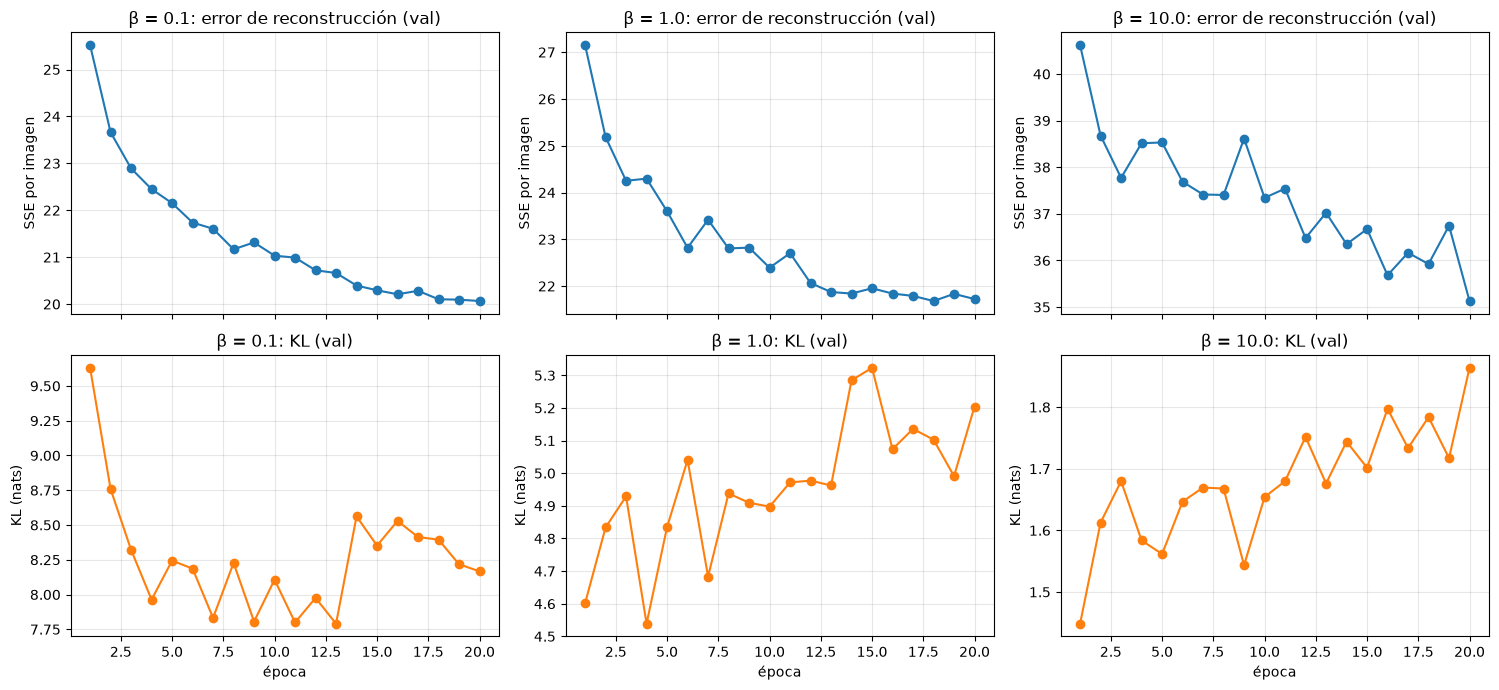

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
ep_axis = range(1, epochs + 1)
for j, b in enumerate(beta_values):
    axes[0, j].plot(ep_axis, hist[b]["val_rec"], marker="o", color="C0")
    axes[0, j].set_title(f"β = {b}: error de reconstrucción (val)")
    axes[0, j].set_ylabel("SSE por imagen")
    axes[1, j].plot(ep_axis, hist[b]["val_kl"], marker="o", color="C1")
    axes[1, j].set_title(f"β = {b}: KL (val)")
    axes[1, j].set_ylabel("KL (nats)"); axes[1, j].set_xlabel("época")
    for r in range(2): axes[r, j].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Task 1.3 - Figuras

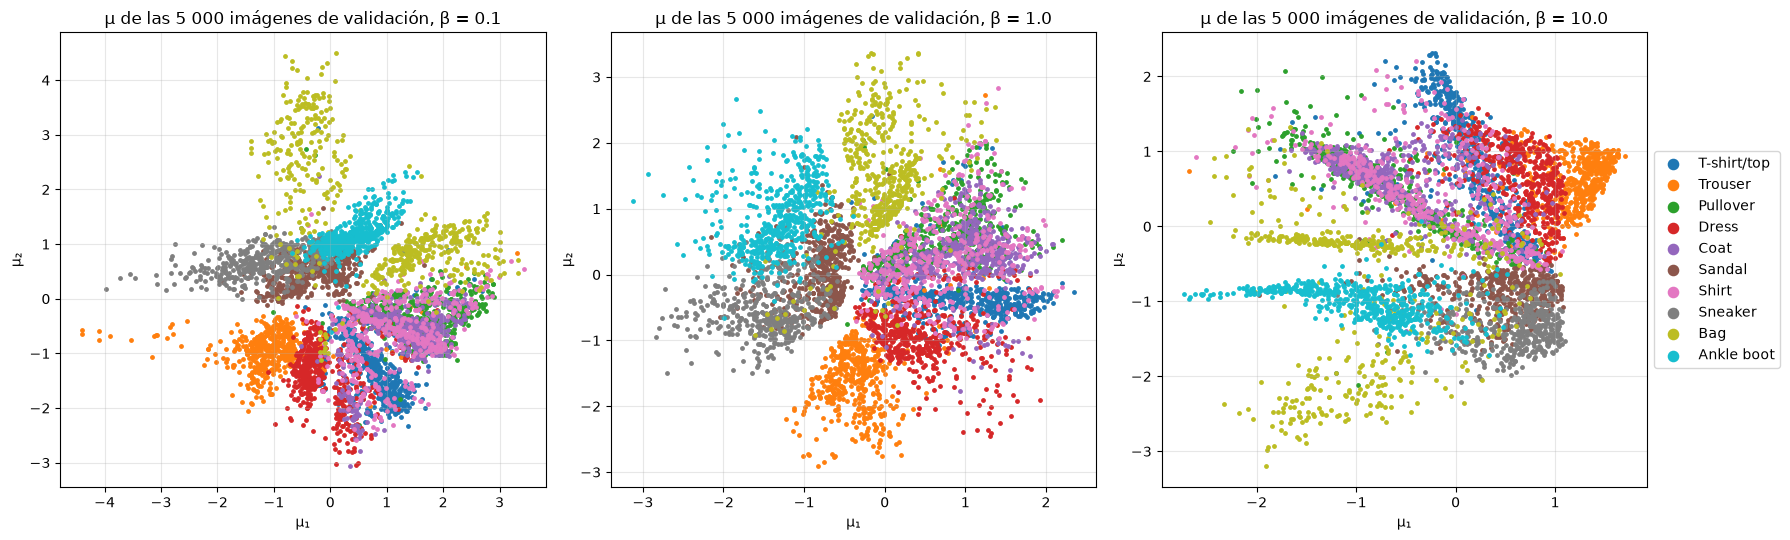

In [5]:
@torch.no_grad()
def get_mu(model, X, bs=1000):
    model.eval()
    return torch.cat([model.encode(xb)[0] for xb in batches(X, bs, shuffle=False)]).cpu()

def mosaic(imgs, nrow, ncol):
    """imgs: (nrow*ncol, 784) en orden de filas -> imagen (nrow*28, ncol*28)."""
    return imgs.reshape(nrow, ncol, 28, 28).permute(0, 2, 1, 3).reshape(nrow * 28, ncol * 28)


fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, b in zip(axes, beta_values):
    mu_va = get_mu(models[b], X_va_f).numpy()
    for k in range(10):
        m = (y_va.numpy() == k)
        ax.scatter(mu_va[m, 0], mu_va[m, 1], s=6, color=plt.cm.tab10(k), label=CLASSES[k])
    ax.set_title(f"μ de las 5 000 imágenes de validación, β = {b}")
    ax.set_xlabel("μ₁"); ax.set_ylabel("μ₂"); ax.grid(alpha=.3)
axes[-1].legend(markerscale=3, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

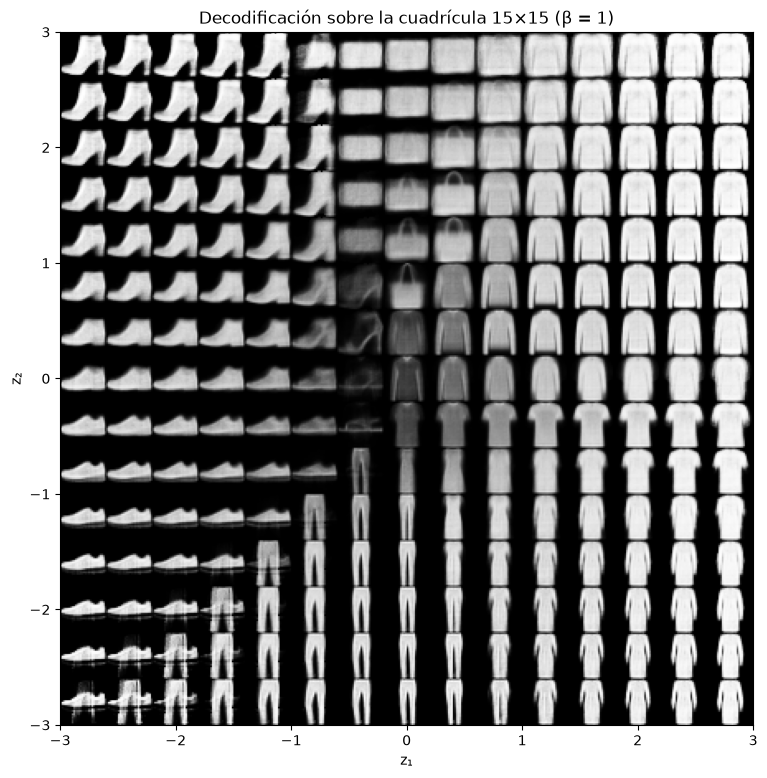

In [6]:

model1 = models[1.0]
g = torch.linspace(-3, 3, 15)
zs = torch.stack([torch.stack([g[j], g[14 - i]]) for i in range(15) for j in range(15)]).to(device)
with torch.no_grad():
    grid_imgs = model1.decode(zs).cpu()
plt.figure(figsize=(9, 9))
plt.imshow(mosaic(grid_imgs, 15, 15), cmap="gray", extent=(-3, 3, -3, 3))
plt.xlabel("z₁"); plt.ylabel("z₂"); plt.title("Decodificación sobre la cuadrícula 15×15 (β = 1)")
plt.show()

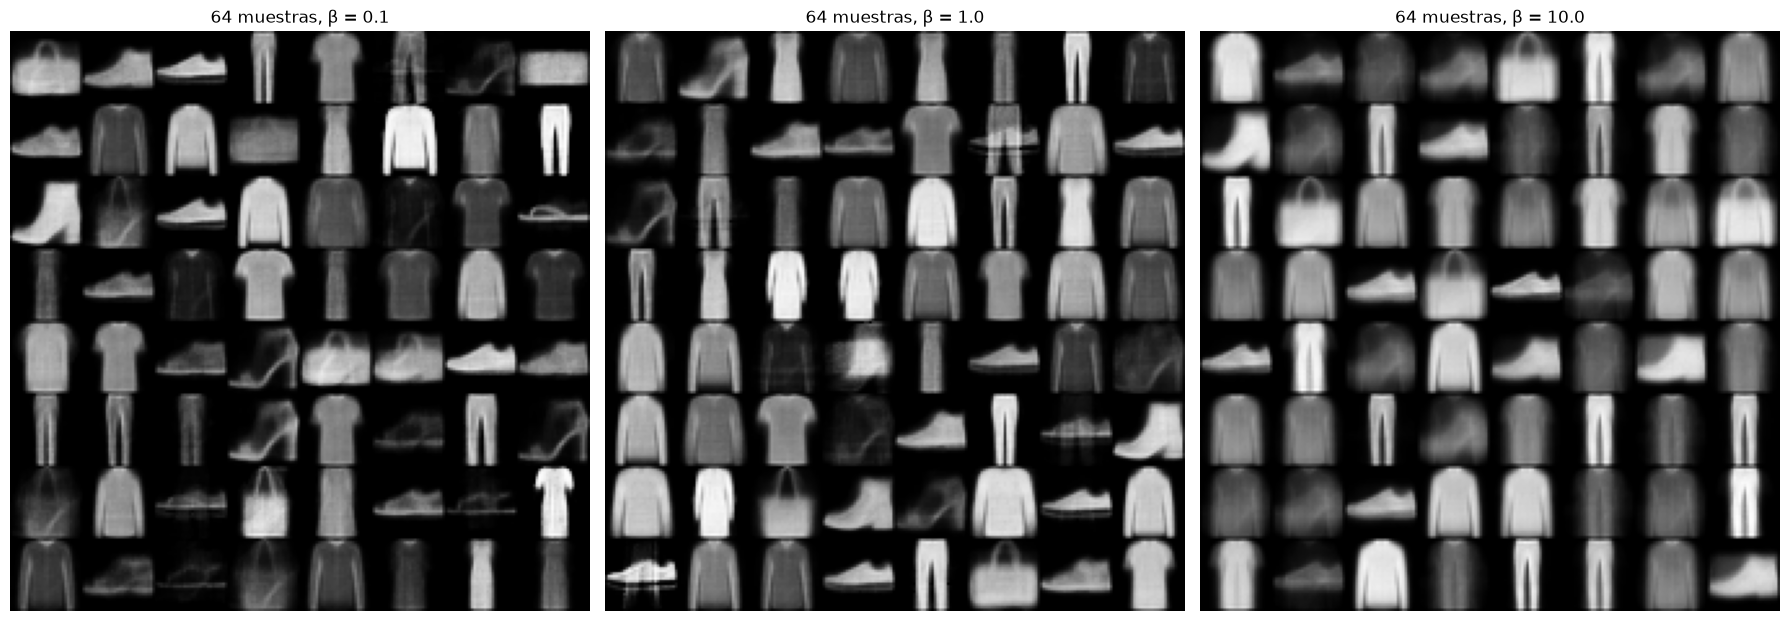

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
set_seed(SEED)
for ax, b in zip(axes, beta_values):
    with torch.no_grad():
        z = torch.randn(64, latent_dim, device=device)
        samp = models[b].decode(z).cpu()
    ax.imshow(mosaic(samp, 8, 8), cmap="gray"); ax.axis("off")
    ax.set_title(f"64 muestras, β = {b}")
plt.tight_layout(); plt.show()

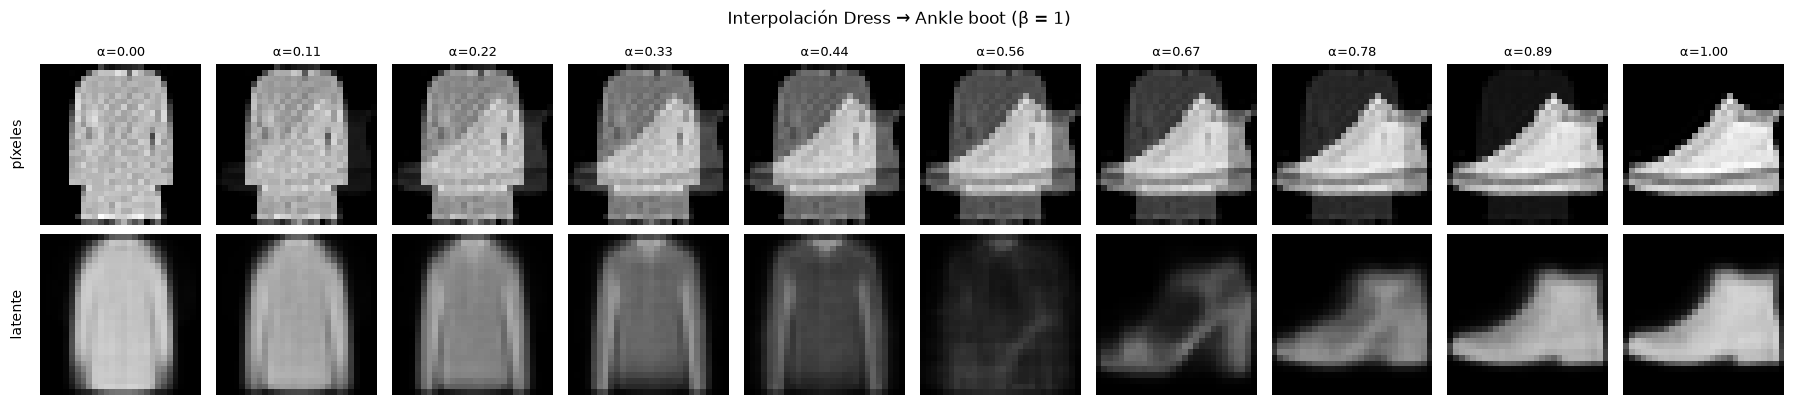

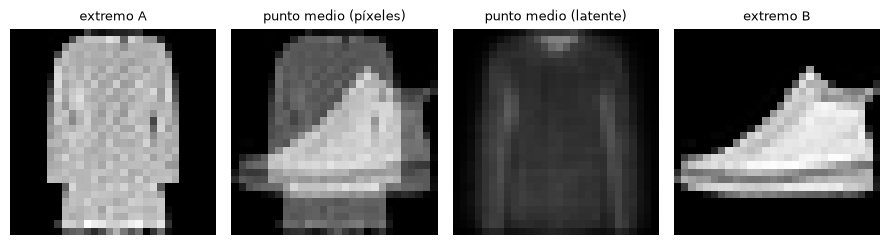

In [8]:

cls_a, cls_b = 3, 9                                
ia = (y_va == cls_a).nonzero()[0].item()
ib = (y_va == cls_b).nonzero()[0].item()
x1, x2 = X_va_f[ia:ia + 1], X_va_f[ib:ib + 1]

alphas = torch.linspace(0, 1, 10, device=device)[:, None]    
with torch.no_grad():
    pix_interp = (1 - alphas) * x1 + alphas * x2
    mu1, _ = model1.encode(x1); mu2, _ = model1.encode(x2)
    lat_interp = model1.decode((1 - alphas) * mu1 + alphas * mu2)

fig, axes = plt.subplots(2, 10, figsize=(18, 4.2))
for k in range(10):
    axes[0, k].imshow(pix_interp[k].reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, k].imshow(lat_interp[k].reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1)
    for r in range(2):
        axes[r, k].axis("off")
    axes[0, k].set_title(f"α={alphas[k].item():.2f}", fontsize=9)
axes[0, 0].text(-0.1, 0.5, "píxeles", transform=axes[0, 0].transAxes, ha="right", va="center", rotation=90)
axes[1, 0].text(-0.1, 0.5, "latente", transform=axes[1, 0].transAxes, ha="right", va="center", rotation=90)
plt.suptitle(f"Interpolación {CLASSES[cls_a]} → {CLASSES[cls_b]} (β = 1)"); plt.tight_layout(); plt.show()

with torch.no_grad():
    mid_pix = 0.5 * x1 + 0.5 * x2
    mid_lat = model1.decode(0.5 * mu1 + 0.5 * mu2)
fig, axes = plt.subplots(1, 4, figsize=(9, 2.8))
for ax, im, tt in zip(axes, [x1, mid_pix, mid_lat, x2],
                      ["extremo A", "punto medio (píxeles)", "punto medio (latente)", "extremo B"]):
    ax.imshow(im.reshape(28, 28).cpu(), cmap="gray", vmin=0, vmax=1); ax.set_title(tt, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Task 1.4 - Análisis

### (a) Tabla final de validación, KL en bits y capacidad de transmitir la clase

In [9]:
rows = []
for b in beta_values:
    kl = hist[b]["val_kl"][-1]
    rows.append({"β": b,
                 "Recon. val (SSE/img)": hist[b]["val_rec"][-1],
                 "KL val (nats)": kl,
                 "KL val (bits)": kl / math.log(2),
                 "log2(10) (bits)": math.log2(10)})
df_final = pd.DataFrame(rows)
display(df_final.round(3))

,β,Recon. val (SSE/img),KL val (nats),KL val (bits),log2(10) (bits)
0,0.1,20.065,8.167,11.782,3.322
1,1.0,21.723,5.204,7.508,3.322
2,10.0,35.130,1.864,2.689,3.322


**Respuesta 1.4(a).**

| β | Recon. val (SSE/img) | KL val (nats) | KL val (bits) |
|---|---:|---:|---:|
| 0.1 | 20.065 | 8.167 | 11.782 |
| 1.0 | 21.723 | 5.204 | 7.508 |
| 10.0 | 35.130 | 1.864 | 2.689 |

Al aumentar β, el error de reconstrucción sube y la KL baja. Para β = 10, la KL media es 2.689 bits, menor que $\log_2 10\approx3.322$ bits. Además,

$$I(y;z)\le I(x;z)\le \mathbb E_x[D_{KL}(q(z\mid x)\Vert p(z))],$$

por lo que el código no tiene capacidad suficiente para identificar sin error una de diez clases equiprobables. En el diagrama de β = 10 todavía se ven grupos gruesos: pantalones, calzado y bolsos ocupan regiones reconocibles. Sin embargo, camiseta, pullover, abrigo, vestido y camisa se superponen bastante. El gráfico coincide con la cota: se conserva información general sobre el tipo de prenda, pero no alcanza para separar todas las clases parecidas.

### (b) Verificación de la KL en forma cerrada por Monte Carlo (β = 1)

In [10]:
idx_img = 0
x_chk = X_va_f[idx_img:idx_img + 1]
with torch.no_grad():
    mu_c, lv_c = model1.encode(x_chk)
mu_c, lv_c = mu_c.double(), lv_c.double()
sigma_c = torch.exp(0.5 * lv_c)
D = mu_c.shape[1]

N_mc = 100_000
set_seed(SEED)
eps = torch.randn(N_mc, D, dtype=torch.float64, device=mu_c.device)
z = mu_c + sigma_c * eps                                                  

# log 
log_q = -0.5 * (((z - mu_c) / sigma_c) ** 2).sum(1) - torch.log(sigma_c).sum() - 0.5 * D * math.log(2 * math.pi)
log_p = -0.5 * (z ** 2).sum(1) - 0.5 * D * math.log(2 * math.pi)
d = log_q - log_p

#MC
kl_mc = d.mean().item()
se_mc = (d.std() / math.sqrt(N_mc)).item()                                  
kl_cf = kl_closed_form(mu_c, lv_c).item()
rel_err = abs(kl_mc - kl_cf) / kl_cf
print(f"mu = {mu_c.cpu().numpy().ravel()}, sigma = {sigma_c.cpu().numpy().ravel()}")
print(f"KL forma cerrada : {kl_cf:.6f} nats")
print(f"KL Monte Carlo   : {kl_mc:.6f} nats  (N = {N_mc})")
print(f"Error relativo   : {rel_err:.3e}")
print(f"Error estándar MC: {se_mc:.3e}  ->  |MC - cerrada| / SE = {abs(kl_mc - kl_cf) / se_mc:.2f}")

mu = [1.54149485 0.26289716], sigma = [0.17094793 0.09206738]
KL forma cerrada : 4.393141 nats
KL Monte Carlo   : 4.398244 nats  (N = 100000)
Error relativo   : 1.161e-03
Error estándar MC: 3.193e-03  ->  |MC - cerrada| / SE = 1.60


**Respuesta 1.4(b).** Para la imagen de validación 0 con el modelo de β = 1 se obtuvo $\mu=(1.541,\,0.263)$ y $\sigma=(0.171,\,0.092)$.

| método | KL (nats) |
|---|---:|
| forma cerrada | 4.393141 |
| Monte Carlo ($N=10^5$) | 4.398244 |
| diferencia absoluta | 0.005103 |
| error relativo | 0.001161 (0.116 %) |

El error estándar estimado fue $3.193\times10^{-3}$. La diferencia equivale a 1.60 errores estándar, por lo que es compatible con la variabilidad esperada de una estimación Monte Carlo de este tamaño. No aparece evidencia de un error de signo o de un factor constante en la fórmula cerrada.

### (c) Región no reconocible e interpolaciones

**Respuesta 1.4(c).** En la cuadrícula de β = 1, la zona alrededor de $z_1\approx-0.5$ y $z_2\approx0$ produce imágenes oscuras o ambiguas. También aparecen mezclas poco reconocibles en algunas esquinas, donde casi no hay códigos de entrenamiento. La KL acerca los posteriores al prior $\mathcal N(0,I)$, pero con dos dimensiones varias clases ocupan regiones cercanas. En las fronteras, el decoder minimiza el error cuadrático produciendo un promedio de prendas compatibles con el mismo punto. En los extremos de la cuadrícula, el decoder extrapola porque el prior asigna poca masa a esos puntos.

En el punto medio de la interpolación en píxeles se superponen el vestido y la bota; se distinguen ambas siluetas y el resultado no parece una imagen real. En el espacio latente aparece una sola prenda vertical, borrosa y ambigua. La diferencia se debe a que la primera operación promedia intensidades, mientras la segunda decodifica un punto de la representación aprendida. La trayectoria latente pasa por regiones ocupadas por otras prendas y no tiene que conservar simultáneamente las dos siluetas originales.

In [11]:
def sharpness(imgs_flat):
    """Magnitud media de la diferencia entre píxeles horizontalmente adyacentes."""
    im = imgs_flat.reshape(-1, 28, 28)
    return (im[:, :, 1:] - im[:, :, :-1]).abs().mean().item()

set_seed(SEED)
sharp = {"reales (1000 val)": sharpness(X_va_f[:1000])}
for b in beta_values:
    with torch.no_grad():
        z = torch.randn(1000, latent_dim, device=device)
        gen = models[b].decode(z)
    sharp[f"generadas β={b}"] = sharpness(gen)
df_sharp = pd.DataFrame({"nitidez": sharp}).round(4)
display(df_sharp)

,nitidez
reales (1000 val),0.0891
generadas β=0.1,0.0436
generadas β=1.0,0.0509
generadas β=10.0,0.0435


### (d) Nitidez y relación con $\sigma_x^2$

**Respuesta 1.4(d).**

| origen | nitidez | fracción de la nitidez real |
|---|---:|---:|
| reales (1,000) | 0.0891 | 1.00 |
| generadas β = 0.1 | 0.0436 | 0.49 |
| generadas β = 1 | 0.0509 | 0.57 |
| generadas β = 10 | 0.0435 | 0.49 |

Las muestras generadas alcanzan aproximadamente la mitad de la nitidez real. La métrica no cambia de forma monótona con β porque también depende del contraste, el tamaño de la silueta y de si una muestra del prior cae en una región bien cubierta del espacio latente.

Para un decoder gaussiano,

$$-log p(x\mid z)=\frac{\lVert x-\hat x\rVert^2}{2\sigma_x^2}+\frac{784}{2}\log(2\pi\sigma_x^2).$$

Al sumar la KL y multiplicar el ELBO negativo por $2\sigma_x^2$, se obtiene

$$\lVert x-\hat x\rVert^2+2\sigma_x^2D_{KL}.$$

Comparando con $\mathcal L_\beta=\lVert x-\hat x\rVert^2+\beta D_{KL}$ resulta $\sigma_x^2=\beta/2$. El error cuadrático hace que el decoder aproxime la media de todas las imágenes compatibles con un código. Con solo dos dimensiones, esa media pierde bordes y detalles. Un β grande añade pérdida de información por la regularización; un β pequeño deja huecos entre los códigos y las muestras del prior pueden caer en zonas que el decoder vio poco. Ambos efectos explican por qué las muestras son más borrosas que las imágenes reales.

## Task 2.1 - Proceso forward

In [12]:
T = 1000
beta_start, beta_end = 1e-4, 0.02

#-1 1
X2_all = X_all * 2.0 - 1.0                       
X2_va  = X2_all[55000:]


betas_lin  = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
alphas_lin = 1.0 - betas_lin
abar_lin   = torch.cumprod(alphas_lin, dim=0)

def q_sample(x0, t, eps, abar):
    """x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps. t: LongTensor (B,) con valores en 1..T."""
    ab = abar.to(device=x0.device, dtype=x0.dtype)[t.to(x0.device) - 1]
    ab = ab.reshape(-1, *([1] * (x0.dim() - 1)))
    return ab.sqrt() * x0 + (1.0 - ab).sqrt() * eps

print("beta_1 =", betas_lin[0].item(), "| beta_T =", betas_lin[-1].item(),
      "| abar_T =", abar_lin[-1].item())

beta_1 = 0.0001 | beta_T = 0.02 | abar_T = 4.0358297653756754e-05


## Task 2.2 - Verificación empírica de la fórmula cerrada

In [13]:
set_seed(SEED)
N_copies, t_check = 5000, 300
x0_fix = X2_va[0].to(device)                               
x = x0_fix.expand(N_copies, 28, 28).clone()

for s in range(t_check):                                   
    eps_s = torch.randn_like(x)                             
    x = alphas_lin[s].sqrt().item() * x + betas_lin[s].sqrt().item() * eps_s

x64 = x.double()
emp_mean = x64.mean(0)
emp_var  = x64.var(0, unbiased=True)
abar_t   = abar_lin[t_check - 1].item()
th_mean  = math.sqrt(abar_t) * x0_fix.double()
th_var   = 1.0 - abar_t

err_mean = (emp_mean - th_mean).abs()
se_mean  = math.sqrt(th_var / N_copies)                       
z_scores = err_mean / se_mean
print(f"abar_300 = {abar_t:.6f} | var teórica = {th_var:.6f}")
print(f"Error máximo absoluto de la media : {err_mean.max().item():.5f}")
print(f"Error estándar esperado  sqrt(var/N) = {se_mean:.5f}")
print(f"max |error| / SE = {z_scores.max().item():.2f}   (esperado ≈ 3.2 para el máximo de 784 píxeles)")
print(f"Fracción de píxeles con |error| < 2·SE = {(z_scores < 2).double().mean().item():.3f}  (esperado ≈ 0.954)")
print(f"Varianza empírica promedio = {emp_var.mean().item():.6f}  vs teórica = {th_var:.6f}")
print(f"Error estándar de la varianza (1 píxel) = {th_var * math.sqrt(2 / (N_copies - 1)):.5f}; "
      f"error estándar del promedio sobre 784 píxeles = {th_var * math.sqrt(2 / (N_copies - 1)) / math.sqrt(784):.6f}")

abar_300 = 0.396420 | var teórica = 0.603580


Error máximo absoluto de la media : 0.03549
Error estándar esperado  sqrt(var/N) = 0.01099
max |error| / SE = 3.23   (esperado ≈ 3.2 para el máximo de 784 píxeles)
Fracción de píxeles con |error| < 2·SE = 0.954  (esperado ≈ 0.954)
Varianza empírica promedio = 0.602884  vs teórica = 0.603580
Error estándar de la varianza (1 píxel) = 0.01207; error estándar del promedio sobre 784 píxeles = 0.000431


**Respuesta 2.2.** Con $N=5000$ copias y $t=300$ se obtuvo $\bar\alpha_{300}=0.396420$, por lo que la varianza teórica es $1-\bar\alpha_{300}=0.603580$.

- Error máximo absoluto de la media: 0.03549.
- Error estándar de la media: $\sqrt{0.603580/5000}=0.01099$.
- Cociente máximo: $0.03549/0.01099=3.23$.
- Varianza empírica promedio: 0.602884.

Para 784 píxeles independientes, observar un máximo cercano a 3.2 errores estándar es razonable. Además, 95.4 % de los píxeles quedó dentro de dos errores estándar, igual al porcentaje esperado para una normal. La diferencia de varianzas fue $6.96\times10^{-4}$, unas 1.61 veces el error estándar estimado para el promedio de las 784 varianzas. Los resultados son compatibles con la fórmula cerrada y con la variabilidad de 5,000 simulaciones.

## Task 2.3 — Visualización, SNR y tiempos clave

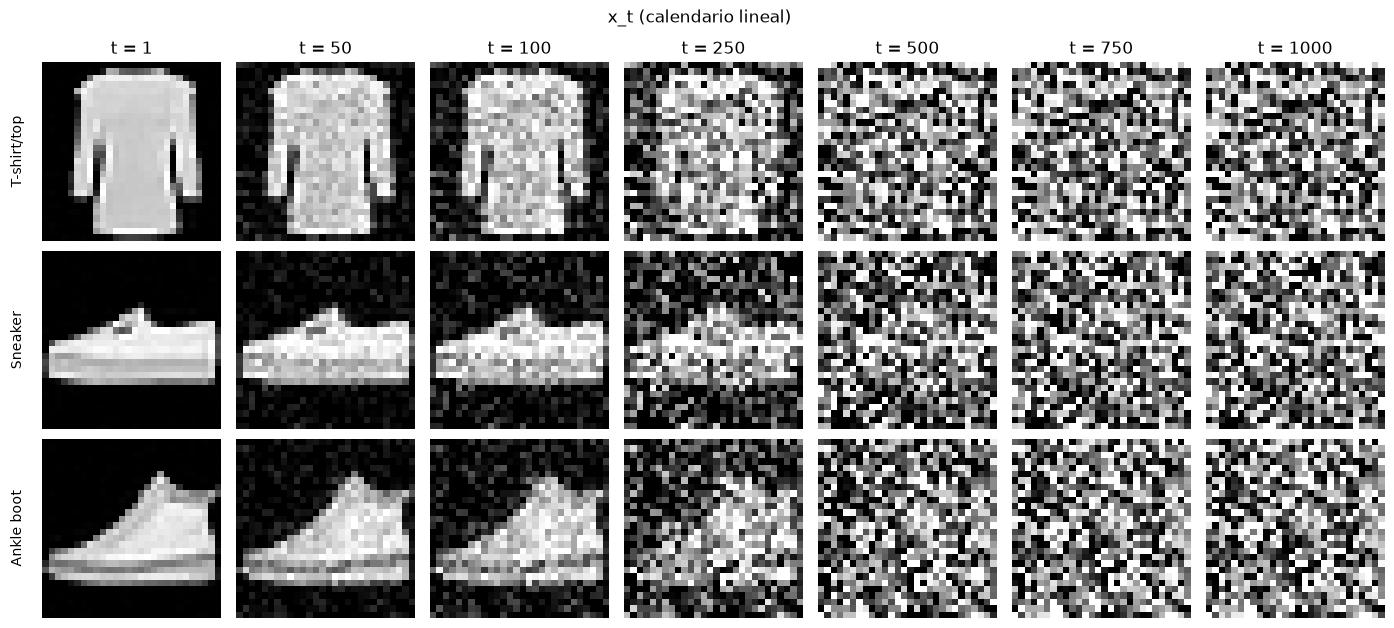

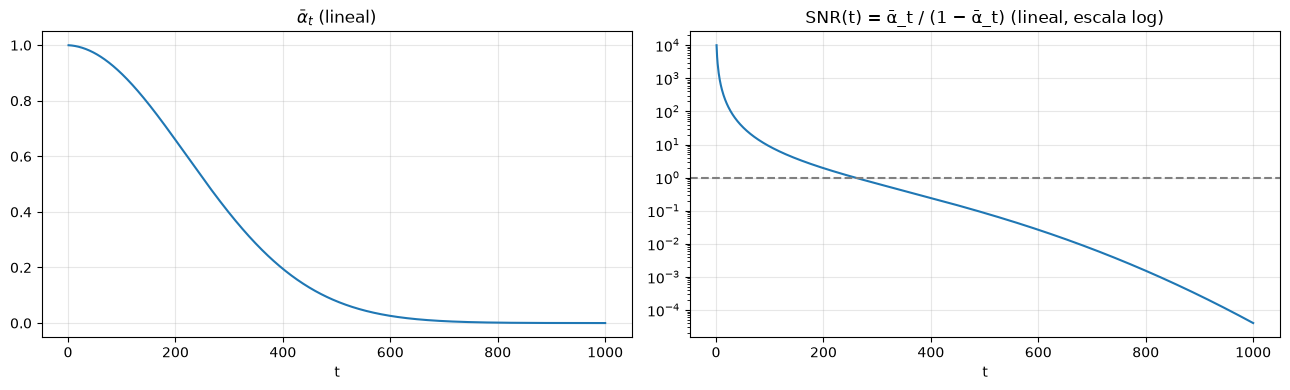

Primer t con SNR(t) < 1      : 260
Primer t con abar_t < 0.01   : 674


In [14]:
set_seed(SEED)
ts_vis = [1, 50, 100, 250, 500, 750, 1000]
cls_vis = [0, 7, 9]                                        
fig, axes = plt.subplots(3, len(ts_vis), figsize=(14, 6.4))
for r, c in enumerate(cls_vis):
    i = (y_va == c).nonzero()[0].item()
    x0 = X2_va[i]
    e = torch.randn_like(x0)                                 
    for k, t in enumerate(ts_vis):
        xt = q_sample(x0[None], torch.tensor([t]), e[None], abar_lin)[0]
        axes[r, k].imshow(xt.clamp(-1, 1), cmap="gray", vmin=-1, vmax=1); axes[r, k].axis("off")
        if r == 0: axes[r, k].set_title(f"t = {t}")
    axes[r, 0].text(-0.1, 0.5, CLASSES[c], transform=axes[r, 0].transAxes, ha="right", va="center", rotation=90)
plt.suptitle("x_t (calendario lineal)"); plt.tight_layout(); plt.show()

t_axis = np.arange(1, T + 1)
snr_lin = abar_lin / (1.0 - abar_lin)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t_axis, abar_lin.numpy()); axes[0].set_title(r"$\bar\alpha_t$ (lineal)"); axes[0].set_xlabel("t"); axes[0].grid(alpha=.3)
axes[1].semilogy(t_axis, snr_lin.numpy()); axes[1].axhline(1, color="gray", ls="--")
axes[1].set_title("SNR(t) = ᾱ_t / (1 − ᾱ_t) (lineal, escala log)"); axes[1].set_xlabel("t"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

t_snr1  = int((snr_lin < 1).nonzero()[0].item()) + 1
t_abar1 = int((abar_lin < 0.01).nonzero()[0].item()) + 1
print("Primer t con SNR(t) < 1      :", t_snr1)
print("Primer t con abar_t < 0.01   :", t_abar1)

**Respuesta 2.3.** Con el calendario lineal: el primer $t$ con SNR(t) < 1 (equivalente a $\bar\alpha_t<0.5$) es **t = 260**, y el primer $t$ con $\bar\alpha_t<0.01$ es **t = 674**. En las figuras se aprecia que hacia t ≈ 250 ya no se distingue bien la prenda, y desde t ≈ 750 la imagen es ruido prácticamente puro.

## Task 2.4 - Segundo calendario

**Base en la literatura:** calendario coseno de Nichol & Dhariwal, *Improved Denoising Diffusion Probabilistic Models* (ICML 2021): $\bar\alpha_t=f(t)/f(0)$, $f(t)=\cos^2\!\Big(\frac{t/T+s}{1+s}\cdot\frac\pi2\Big)$, con $s=0.008$.

**Modificación propia:** el coseno original llega a $\bar\alpha_T\approx0$ (SNR = 0 exacto), lo que obliga a recortar $\beta_T$ y deja los últimos pasos como ruido puro. Aquí se **trunca** el tiempo: se evalúa $f$ en $r\,t/T$ con $r<1$ elegido para que $\bar\alpha_T=10^{-4}$ exactamente (cumple $<10^{-3}$) y todos los $\beta_t$ salen de $\beta_t=1-\bar\alpha_t/\bar\alpha_{t-1}$, sin necesidad de recortes.

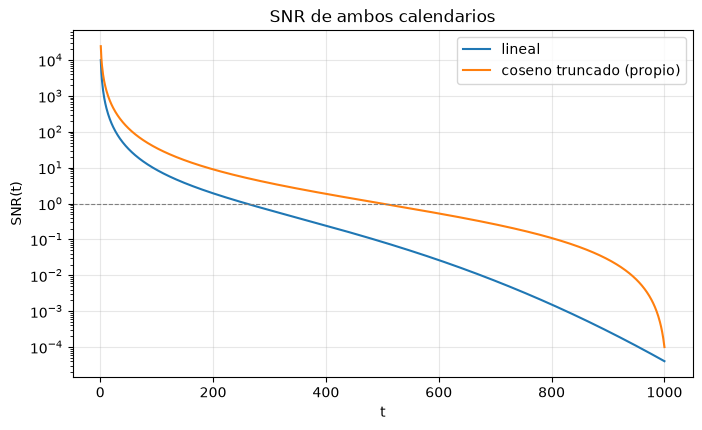

,calendario,abar_T,primer t con SNR<1,beta_min,beta_max
0,lineal,0.00004,260,0.000100,0.020000
1,coseno truncado,0.00010,500,0.000041,0.250176


In [15]:
s_cos, abar_T_target = 0.008, 1e-4
f_cos = lambda u: torch.cos(((u + s_cos) / (1 + s_cos)) * math.pi / 2) ** 2


f0 = f_cos(torch.tensor(0.0, dtype=torch.float64)).item()
r_trunc = math.acos(math.sqrt(abar_T_target * f0)) * 2 / math.pi * (1 + s_cos) - s_cos

t_grid = torch.arange(0, T + 1, dtype=torch.float64)
abar_full = f_cos(r_trunc * t_grid / T) / f_cos(torch.tensor(0.0, dtype=torch.float64))
betas_cos  = 1.0 - abar_full[1:] / abar_full[:-1]
alphas_cos = 1.0 - betas_cos
abar_cos   = torch.cumprod(alphas_cos, dim=0)
assert (betas_cos > 0).all() and (betas_cos < 1).all(), "beta_t debe estar en (0,1)"
assert abar_cos[-1] < 1e-3, "abar_T debe ser < 1e-3"
snr_cos = abar_cos / (1.0 - abar_cos)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(t_axis, snr_lin.numpy(), label="lineal")
ax.semilogy(t_axis, snr_cos.numpy(), label="coseno truncado (propio)")
ax.axhline(1, color="gray", ls="--", lw=.8)
ax.set_xlabel("t"); ax.set_ylabel("SNR(t)"); ax.set_title("SNR de ambos calendarios"); ax.legend(); ax.grid(alpha=.3)
plt.show()

df_sched = pd.DataFrame({
    "calendario": ["lineal", "coseno truncado"],
    "abar_T": [abar_lin[-1].item(), abar_cos[-1].item()],
    "primer t con SNR<1": [int((snr_lin < 1).nonzero()[0]) + 1, int((snr_cos < 1).nonzero()[0]) + 1],
    "beta_min": [betas_lin.min().item(), betas_cos.min().item()],
    "beta_max": [betas_lin.max().item(), betas_cos.max().item()],
})
display(df_sched)

**Respuesta 2.4.**

| Calendario | $\bar\alpha_T$ | Primer $t$ con SNR < 1 | $\beta_{\min}$ | $\beta_{\max}$ |
|---|---|---|---|---|
| Lineal | 4.04 × 10⁻⁵ | 260 | 1 × 10⁻⁴ | 0.020 |
| Coseno truncado (propio) | 1.00 × 10⁻⁴ | 500 | 4.1 × 10⁻⁵ | 0.250 |

Ambos cumplen $\bar\alpha_T<10^{-3}$ y $\beta_t\in(0,1)$. En el calendario propio el SNR baja de forma mucho más gradual (SNR = 1 se alcanza en t = 500, frente a 260 del lineal).

## Task 2.5 - Análisis

### (a) Cálculo a mano de $\bar\alpha_T$ para el calendario lineal

Con $\log\bar\alpha_T=\sum_{t=1}^{T}\log(1-\beta_t)\approx-\sum\beta_t-\tfrac12\sum\beta_t^2$, $\beta_1=10^{-4}$, $\beta_T=0.02$, $T=1000$:

1. **Primera suma (aritmética):** $\sum_t\beta_t=\dfrac{T(\beta_1+\beta_T)}{2}=\dfrac{1000\,(10^{-4}+0.02)}{2}=10.05$.
2. **Segunda suma (aproximación integral):** con $\beta(u)=\beta_1+(\beta_T-\beta_1)u$, $u\in[0,1]$:
   $\sum_t\beta_t^2\approx T\!\int_0^1\!\beta(u)^2du=\dfrac{T(\beta_1^2+\beta_1\beta_T+\beta_T^2)}{3}=\dfrac{1000\,(10^{-8}+2\times10^{-6}+4\times10^{-4})}{3}\approx0.1340$, por lo que $\tfrac12\sum\beta_t^2\approx0.0670$.
3. **Resultado:** $\log\bar\alpha_T\approx-10.05-0.0670=-10.117\;\Rightarrow\;\bar\alpha_T\approx e^{-10.117}\approx4.04\times10^{-5}$.

(El siguiente término del desarrollo, $-\tfrac13\sum\beta_t^3\approx-6.7\times10^{-4}$, es despreciable.) La celda siguiente compara con el valor numérico.

In [16]:
S1_exact = betas_lin.sum().item()
S2_exact = (betas_lin ** 2).sum().item()
S1_hand = T * (beta_start + beta_end) / 2
S2_hand = T * (beta_start**2 + beta_start * beta_end + beta_end**2) / 3
abar_hand = math.exp(-S1_hand - 0.5 * S2_hand)
abar_code = abar_lin[-1].item()
abar_code_log = math.exp(torch.log1p(-betas_lin).sum().item())
print(f"Σβ      : a mano {S1_hand:.4f} | código {S1_exact:.4f}")
print(f"Σβ²     : a mano {S2_hand:.5f} | código {S2_exact:.5f}")
print(f"abar_T  : aproximación a mano {abar_hand:.4e} | código (cumprod) {abar_code:.4e} | Σlog(1-β) {abar_code_log:.4e}")
print(f"Error relativo de la aproximación: {abs(abar_hand - abar_code) / abar_code:.2e}")

Σβ      : a mano 10.0500 | código 10.0500
Σβ²     : a mano 0.13400 | código 0.13407
abar_T  : aproximación a mano 4.0387e-05 | código (cumprod) 4.0358e-05 | Σlog(1-β) 4.0358e-05
Error relativo de la aproximación: 7.12e-04


**Respuesta 2.5(a).** La aproximación a mano da $\bar\alpha_T\approx4.039\times10^{-5}$ y el código (producto acumulado) da $4.036\times10^{-5}$: error relativo de 7.1 × 10⁻⁴ (0.07 %). Esa diferencia viene principalmente del término de tercer orden omitido, $-\tfrac13\sum\beta_t^3\approx-6.7\times10^{-4}$ en $\log\bar\alpha_T$, y en mucha menor medida de la aproximación integral de $\sum\beta_t^2$ (0.13400 frente a 0.13407 exacto).

### (b) Pasos con SNR ∈ [0.01, 100] y eficiencia de los calendarios

In [17]:
def regime_counts(snr):
    return {"SNR<0.01 (x_t≈ε)": int((snr < 0.01).sum()),
            "SNR∈[0.01,100]": int(((snr >= 0.01) & (snr <= 100)).sum()),
            "SNR>100 (x_t≈x0)": int((snr > 100).sum())}
df_reg = pd.DataFrame({"lineal": regime_counts(snr_lin), "coseno truncado": regime_counts(snr_cos)}).T
display(df_reg)

,SNR<0.01 (x_t≈ε),"SNR∈[0.01,100]",SNR>100 (x_t≈x0)
lineal,326,647,27
coseno truncado,58,886,56


**Respuesta 2.5(b).**

| Calendario | SNR < 0.01 | SNR ∈ [0.01, 100] | SNR > 100 |
|---|---|---|---|
| Lineal | 326 | **647** | 27 |
| Coseno truncado | 58 | **886** | 56 |

- **SNR ≪ 0.01 ($x_t\approx\epsilon$).** Predecir $\epsilon$ es casi trivial: basta con devolver $x_t$ (la señal es despreciable). El error ya es ≈ 0 y no hay estructura de imagen que aprender, así que estos pasos aportan casi nada al aprendizaje aunque se muestreen con la misma frecuencia que los demás.
- **SNR ≫ 100 ($x_t\approx x_0$).** Aquí el ruido es una perturbación diminuta sobre la imagen. Predecir $\epsilon$ exige separar un ruido de amplitud $\sqrt{1-\bar\alpha_t}$ muy pequeña de una imagen desconocida: cualquier error al estimar $x_0$ se amplifica por $1/\sqrt{1-\bar\alpha_t}$. La tarea es difícil y ruidosa, y lo que se aprende son detalles casi imperceptibles, con poco aporte a la calidad global de la muestra.
- **SNR ∈ [0.01, 100].** Señal y ruido son comparables: la red tiene que usar la estructura de la imagen para separarlos. Aquí se concentra el aprendizaje útil.

Con $t$ sorteado uniformemente, la fracción de iteraciones útiles es (pasos con SNR ∈ [0.01,100]) / T: **64.7 % con el calendario lineal frente a 88.6 % con el coseno truncado**. El lineal desperdicia el 32.6 % de los pasos (326) en la zona de ruido casi puro, frente al 5.8 % del coseno. Por tanto, **el calendario coseno truncado es más eficiente**. (Tiene algo más de pasos con SNR > 100, 56 frente a 27, pero muchos menos en el régimen trivial.)

### (c) Varianza global de $x_t$

**Demostración.** Sea $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$ con $\epsilon\sim\mathcal{N}(0,I)$ independiente de $x_0$. Para la varianza global (todos los píxeles de todas las imágenes, tomados como una sola población):

$$\mathrm{Var}(x_t)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t)\,\mathrm{Var}(\epsilon)+2\sqrt{\bar\alpha_t(1-\bar\alpha_t)}\,\mathrm{Cov}(x_0,\epsilon).$$

Como $\epsilon$ es independiente de $x_0$, $\mathrm{Cov}(x_0,\epsilon)=0$, y $\mathrm{Var}(\epsilon)=1$, por lo que

$$\mathrm{Var}(x_t)=\bar\alpha_t\,\mathrm{Var}(x_0)+(1-\bar\alpha_t).\;\;\blacksquare$$

In [18]:
set_seed(SEED)
X2_train = X2_all[:55000]  # solo el split de entrenamiento
var0 = X2_train.double().var(unbiased=False).item()
print(f"Var(x0) sobre entrenamiento en [-1,1]: {var0:.6f}")

rows = []
for t in [1, 250, 500, 1000]:
    e = torch.randn_like(X2_train)
    tt = torch.full((X2_train.shape[0],), t, dtype=torch.long)
    xt = q_sample(X2_train, tt, e, abar_lin)
    emp = xt.double().var(unbiased=False).item()
    ab = abar_lin[t - 1].item()
    pred = ab * var0 + (1 - ab)
    rows.append({"t": t, "abar_t": ab, "Var empírica": emp, "Var predicha": pred, "dif. abs.": abs(emp - pred)})
    del e, xt
display(pd.DataFrame(rows))

Var(x0) sobre entrenamiento en [-1,1]: 0.498259


,t,abar_t,Var empírica,Var predicha,dif. abs.
0,1,0.999900,0.498304,0.498309,0.000005
1,250,0.524085,0.737226,0.737045,0.000182
2,500,0.078587,0.960343,0.960570,0.000227
3,1000,0.000040,1.000391,0.999980,0.000411


**Respuesta 2.5(c).** La varianza sobre las 55,000 imágenes del split de entrenamiento, escaladas a $[-1,1]$, fue $\operatorname{Var}(x_0)=0.498259$.

| $t$ | $\bar\alpha_t$ | var. empírica | var. predicha | diferencia absoluta |
|---:|---:|---:|---:|---:|
| 1 | 0.999900 | 0.498304 | 0.498309 | 0.000005 |
| 250 | 0.524085 | 0.737226 | 0.737045 | 0.000182 |
| 500 | 0.078587 | 0.960343 | 0.960570 | 0.000227 |
| 1000 | 0.000040 | 1.000391 | 0.999980 | 0.000411 |

Con $55,000\times784\approx4.31\times10^7$ valores, el error estándar de una varianza cercana a uno es aproximadamente $\sqrt{2/N}=2.15\times10^{-4}$. La mayor diferencia equivale a 1.91 errores estándar y sigue siendo compatible con ruido de muestreo.

En $t=T$, la varianza predicha es 0.999980 y la media queda cerca de cero porque $\sqrt{\bar\alpha_T}$ es muy pequeña. Esto permite iniciar la generación con $x_T\sim\mathcal N(0,I)$. Si quedara una varianza distinta de uno o señal visible de $x_0$, el proceso inverso empezaría desde una distribución diferente de la usada durante el entrenamiento.

# Task 3 - Modelo de difusión condicional

## Task 3.1 - U-Net y condicionamiento

La red sigue el esquema de la presentación S14: recibe $x_t$, el instante $t$ y la clase $c$, y predice el ruido añadido. El embedding sinusoidal representa el instante con senos y cosenos de distintas frecuencias. El embedding de clase usa once entradas; la clase 10 representa la condición nula. Ambos embeddings se suman y se inyectan en cada bloque convolucional.

La resolución baja de $28\times28$ con 32 canales a $14\times14$ con 64 canales. El cuello de botella conserva $14\times14$. El decoder concatena las activaciones del encoder antes de cada bloque de subida.

In [19]:
class SinusoidalTimeEmbedding(nn.Module):
    '''Positional encoding sinusoidal usado para representar t.'''
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freq = torch.exp(
            -math.log(10000) * torch.arange(half, device=t.device) / half
        )
        angles = t.float()[:, None] * freq[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=1)


class ConditionalBlock(nn.Module):
    '''Bloque convolucional que suma la condición con broadcasting.'''
    def __init__(self, in_channels, out_channels, cond_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.cond_proj = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, out_channels))
        self.skip = (nn.Identity() if in_channels == out_channels
                     else nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x, cond):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.cond_proj(cond)[:, :, None, None]
        h = self.norm2(self.conv2(F.silu(h)))
        return F.silu(h + self.skip(x))


class ConditionalUNet(nn.Module):
    def __init__(self, cond_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(cond_dim),
            nn.Linear(cond_dim, cond_dim), nn.SiLU(),
            nn.Linear(cond_dim, cond_dim),
        )
        self.class_emb = nn.Embedding(11, cond_dim)

        self.enc28 = ConditionalBlock(1, 32, cond_dim)
        self.down = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.enc14 = ConditionalBlock(64, 64, cond_dim)
        self.bottleneck = ConditionalBlock(64, 64, cond_dim)

        # Se concatenan las dos conexiones de salto, una por resolución.
        self.dec14 = ConditionalBlock(128, 64, cond_dim)
        self.up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec28 = ConditionalBlock(64, 32, cond_dim)
        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x, t, c):
        cond = self.time_mlp(t) + self.class_emb(c)
        h28 = self.enc28(x, cond)
        h14 = self.enc14(self.down(h28), cond)
        middle = self.bottleneck(h14, cond)
        h14_up = self.dec14(torch.cat([middle, h14], dim=1), cond)
        h28_up = self.up(h14_up)
        return self.out(self.dec28(torch.cat([h28_up, h28], dim=1), cond))


set_seed(SEED)
diffusion_model = ConditionalUNet().to(device)
n_params = sum(p.numel() for p in diffusion_model.parameters())
print(f"Parámetros entrenables: {n_params:,}")

# Comprobación de formas pedidas en el enunciado.
with torch.no_grad():
    test_out = diffusion_model(
        torch.zeros(2, 1, 28, 28, device=device),
        torch.tensor([1, T], device=device),
        torch.tensor([0, 10], device=device),
    )
print("Forma de salida:", tuple(test_out.shape))

Parámetros entrenables: 373,889


Forma de salida: (2, 1, 28, 28)


## Task 3.2 - Entrenamiento y pérdida por intervalo

En cada iteración se sortea $t$ de forma uniforme y se construye $x_t$ con la fórmula cerrada de la Task 2.1. La clase se reemplaza por 10 con probabilidad $p_{uncond}=0.1$. La pérdida es el MSE entre el ruido real y el ruido predicho, como se mostró en la sección de difusión de S14.

Época 01/30: pérdida = 0.12612


Época 02/30: pérdida = 0.06181


Época 03/30: pérdida = 0.05413


Época 04/30: pérdida = 0.05070


Época 05/30: pérdida = 0.04808


...

Época 26/30: pérdida = 0.03990


Época 27/30: pérdida = 0.03973


Época 28/30: pérdida = 0.03942


Época 29/30: pérdida = 0.03924


Época 30/30: pérdida = 0.03875
Tiempo total de entrenamiento: 10.90 min


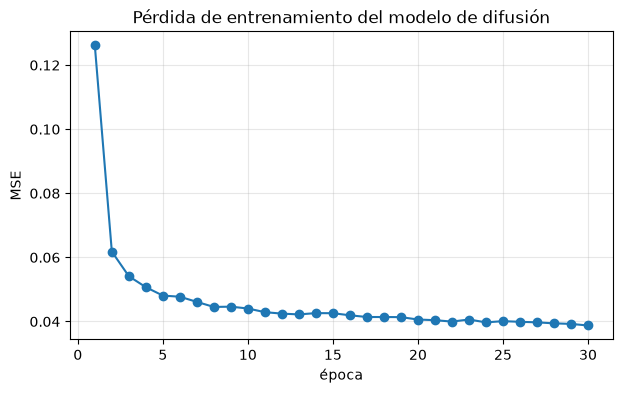

In [20]:
import time
from IPython.display import Markdown, display

diff_epochs = 30
diff_lr = 2e-4
p_uncond = 0.1

X2_tr_img = (X_tr * 2.0 - 1.0).unsqueeze(1)
X2_va_img = (X_va * 2.0 - 1.0).unsqueeze(1)


def labeled_batches(X, y, bs, shuffle=True):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for start in range(0, len(X), bs):
        take = idx[start:start + bs]
        yield X[take], y[take]


set_seed(SEED)
diffusion_model = ConditionalUNet().to(device)
optimizer = torch.optim.Adam(diffusion_model.parameters(), lr=diff_lr)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
diff_train_loss = []

train_start = time.perf_counter()
for epoch in range(1, diff_epochs + 1):
    diffusion_model.train()
    loss_sum = 0.0
    seen = 0
    for xb_cpu, yb_cpu in labeled_batches(X2_tr_img, y_tr, batch_size, shuffle=True):
        xb = xb_cpu.to(device, non_blocking=True)
        yb = yb_cpu.to(device, non_blocking=True)
        t = torch.randint(1, T + 1, (len(xb),), device=device)
        eps = torch.randn_like(xb)
        xt = q_sample(xb, t, eps, abar_lin)
        c = yb.clone()
        c[torch.rand(len(c), device=device) < p_uncond] = 10

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=use_amp):
            pred = diffusion_model(xt, t, c)
            loss = F.mse_loss(pred, eps)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        loss_sum += loss.item() * len(xb)
        seen += len(xb)
    epoch_loss = loss_sum / seen
    diff_train_loss.append(epoch_loss)
    print(f"Época {epoch:02d}/{diff_epochs}: pérdida = {epoch_loss:.5f}")

diff_train_seconds = time.perf_counter() - train_start
print(f"Tiempo total de entrenamiento: {diff_train_seconds / 60:.2f} min")

plt.figure(figsize=(7, 4))
plt.plot(range(1, diff_epochs + 1), diff_train_loss, marker="o")
plt.xlabel("época"); plt.ylabel("MSE")
plt.title("Pérdida de entrenamiento del modelo de difusión")
plt.grid(alpha=.3); plt.show()

,intervalo t,MSE validación
0,1-100,0.21196
1,101-200,0.08154
2,201-300,0.04667
3,301-400,0.02734
4,401-500,0.01504
5,501-600,0.00717
6,601-700,0.00276
7,701-800,0.00083
8,801-900,0.00024
9,901-1000,0.00011


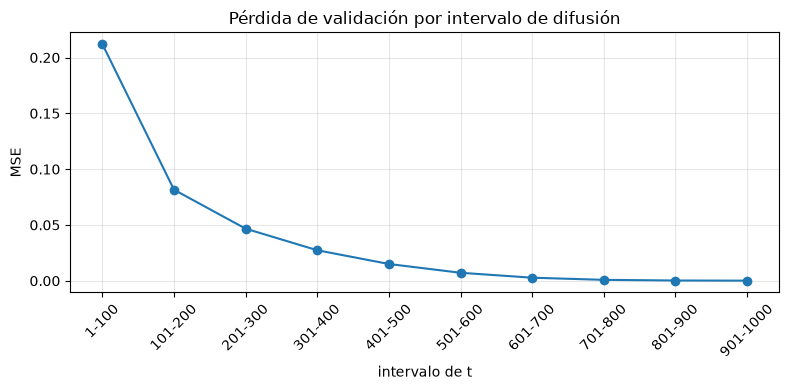

In [21]:
@torch.no_grad()
def validation_loss_by_interval(model):
    '''Cada intervalo se evalúa con las 5,000 imágenes y un t aleatorio dentro del intervalo.'''
    model.eval()
    values = []
    set_seed(SEED + 1)
    for interval in range(10):
        total = 0.0
        count = 0
        low, high = interval * 100 + 1, (interval + 1) * 100 + 1
        for xb_cpu, yb_cpu in labeled_batches(X2_va_img, y_va, batch_size, shuffle=False):
            xb = xb_cpu.to(device)
            yb = yb_cpu.to(device)
            t = torch.randint(low, high, (len(xb),), device=device)
            eps = torch.randn_like(xb)
            pred = model(q_sample(xb, t, eps, abar_lin), t, yb)
            per_image = (pred - eps).pow(2).flatten(1).mean(1)
            total += per_image.sum().item()
            count += len(xb)
        values.append(total / count)
    return values


val_interval_loss = validation_loss_by_interval(diffusion_model)
interval_labels = [f"{100*i+1}-{100*(i+1)}" for i in range(10)]
df_interval = pd.DataFrame({"intervalo t": interval_labels, "MSE validación": val_interval_loss})
display(df_interval.round(5))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), val_interval_loss, marker="o")
plt.xticks(range(1, 11), interval_labels, rotation=45)
plt.xlabel("intervalo de t"); plt.ylabel("MSE")
plt.title("Pérdida de validación por intervalo de difusión")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Task 3.3 - Muestreo ancestral

Se parte de $x_T\sim\mathcal N(0,I)$ y se aplican los 1,000 pasos en orden inverso. Para $t=1$ se usa $z=0$. La varianza del ruido de cada paso es $\sigma_t^2=\beta_t$. Los valores solo se recortan a $[-1,1]$ al terminar.

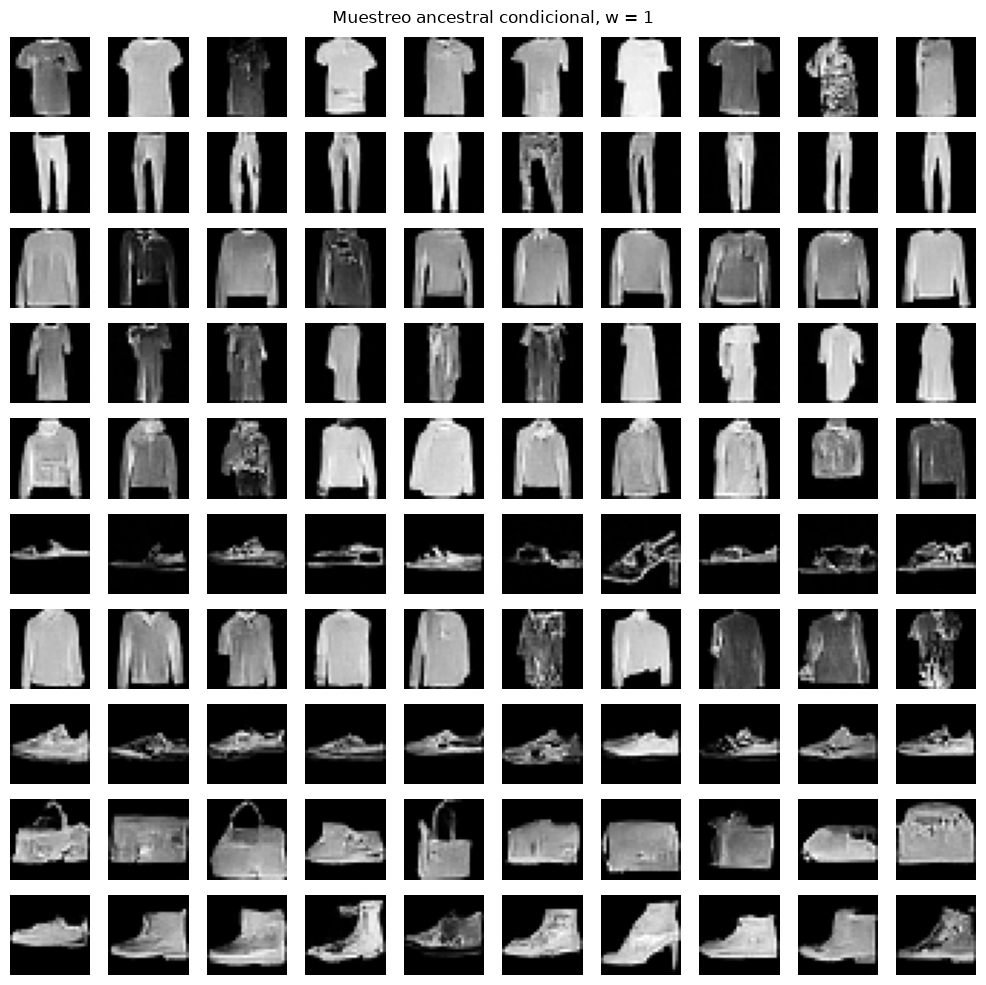

Tiempo para 500 imágenes con w=1: 40.93 s


In [22]:
@torch.no_grad()
def ancestral_sample(model, classes, w=1.0, seed=SEED):
    model.eval()
    set_seed(seed)
    classes = classes.to(device)
    x = torch.randn(len(classes), 1, 28, 28, device=device)

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for step in range(T, 0, -1):
        t = torch.full((len(x),), step, dtype=torch.long, device=device)
        if w == 1.0:
            eps_hat = model(x, t, classes)
        else:
            # Una sola pasada con un lote duplicado calcula condición nula y clase.
            x_both = torch.cat([x, x], dim=0)
            t_both = torch.cat([t, t], dim=0)
            c_both = torch.cat([torch.full_like(classes, 10), classes], dim=0)
            eps_uncond, eps_cond = model(x_both, t_both, c_both).chunk(2)
            eps_hat = eps_uncond + w * (eps_cond - eps_uncond)

        beta_t = betas_lin[step - 1].to(device=device, dtype=x.dtype)
        alpha_t = alphas_lin[step - 1].to(device=device, dtype=x.dtype)
        abar_t = abar_lin[step - 1].to(device=device, dtype=x.dtype)
        mean = (x - (1 - alpha_t) / torch.sqrt(1 - abar_t) * eps_hat) / torch.sqrt(alpha_t)
        if step > 1:
            x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
        else:
            x = mean

    result = x.clamp(-1, 1)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return result.cpu(), elapsed


# Se generan 50 por clase; las primeras 10 de cada clase cubren la Task 3.3
# y el conjunto completo se reutiliza en la Task 3.4.
requested_classes = torch.arange(10).repeat_interleave(50)
samples_w1, sample_time_w1 = ancestral_sample(
    diffusion_model, requested_classes, w=1.0, seed=SEED + 10
)

fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for c in range(10):
    for j in range(10):
        axes[c, j].imshow(samples_w1[c * 50 + j, 0], cmap="gray", vmin=-1, vmax=1)
        axes[c, j].axis("off")
    axes[c, 0].set_ylabel(CLASSES[c], rotation=0, ha="right", va="center")
plt.suptitle("Muestreo ancestral condicional, w = 1")
plt.tight_layout(); plt.show()
print(f"Tiempo para 500 imágenes con w=1: {sample_time_w1:.2f} s")

## Task 3.4 - Guía sin clasificador

Durante el entrenamiento, el reemplazo aleatorio de la clase por la condición nula permite obtener las dos predicciones necesarias. Se usa la convención del enunciado:

$$\tilde\epsilon=\epsilon_\theta(x_t,t,\varnothing)+w\left[\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing)\right].$$

Con $w=1$ queda la predicción condicional pura. Para medir fidelidad se entrena un clasificador con imágenes reales; la diversidad se calcula como la distancia euclidiana promedio entre pares de imágenes de la misma clase.

In [23]:
class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.features(x))


@torch.no_grad()
def classifier_accuracy(model, X, y):
    model.eval()
    correct = total = 0
    for xb_cpu, yb_cpu in labeled_batches(X.unsqueeze(1), y, 512, shuffle=False):
        pred = model(xb_cpu.to(device)).argmax(1).cpu()
        correct += (pred == yb_cpu).sum().item()
        total += len(yb_cpu)
    return correct / total


set_seed(SEED)
classifier = FashionClassifier().to(device)
clf_opt = torch.optim.Adam(classifier.parameters(), lr=1e-3)
clf_history = []
for epoch in range(1, 11):
    classifier.train()
    total_loss = 0.0
    seen = 0
    for xb_cpu, yb_cpu in labeled_batches(X_tr.unsqueeze(1), y_tr, 128, shuffle=True):
        xb, yb = xb_cpu.to(device), yb_cpu.to(device)
        logits = classifier(xb)
        loss = F.cross_entropy(logits, yb)
        clf_opt.zero_grad(set_to_none=True)
        loss.backward()
        clf_opt.step()
        total_loss += loss.item() * len(xb)
        seen += len(xb)
    val_acc = classifier_accuracy(classifier, X_va, y_va)
    clf_history.append((total_loss / seen, val_acc))
    print(f"Época {epoch}: loss={total_loss/seen:.4f}, exactitud val={100*val_acc:.2f}%")
    if val_acc >= 0.88:
        break

assert clf_history[-1][1] >= 0.88, "El clasificador no alcanzó 88% en validación"
classifier_val_accuracy = clf_history[-1][1]

Época 1: loss=0.5354, exactitud val=86.80%


Época 2: loss=0.3284, exactitud val=88.26%


w=3: 81.58 s para 500 imágenes


w=7: 82.84 s para 500 imágenes


,w,fidelidad global,diversidad global,segundos por 100 imágenes
0,1,0.838,14.9273,8.1868
1,3,0.976,13.1091,16.3164
2,7,0.980,12.0806,16.5672


Diversidad de 50 imágenes reales por clase: 17.6752


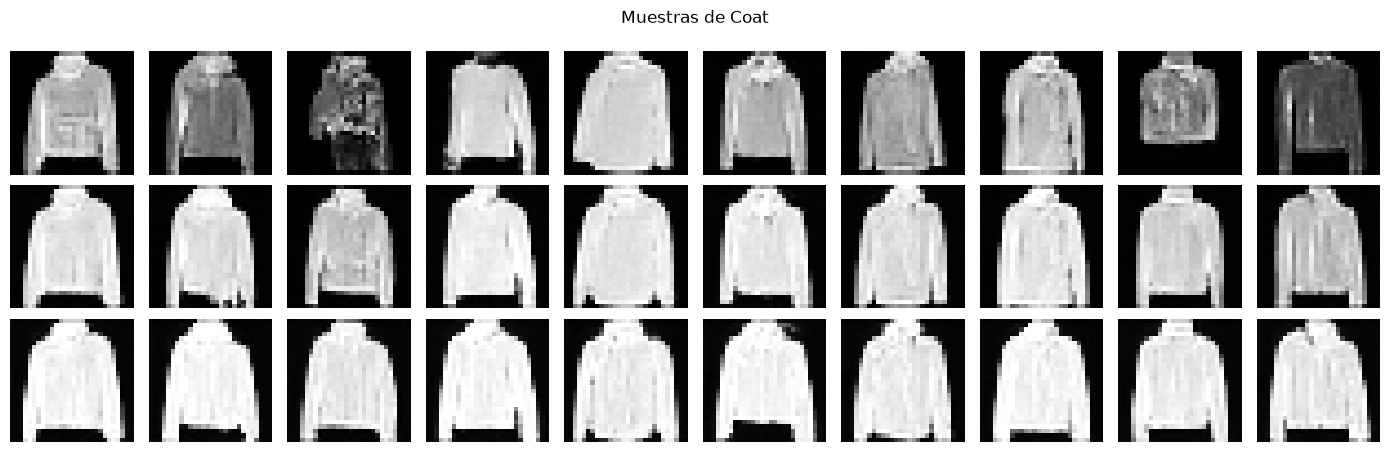

In [24]:
samples_by_w = {1: samples_w1}
times_by_w = {1: sample_time_w1}
for w in [3, 7]:
    samples_by_w[w], times_by_w[w] = ancestral_sample(
        diffusion_model, requested_classes, w=float(w), seed=SEED + 10
    )
    print(f"w={w}: {times_by_w[w]:.2f} s para 500 imágenes")


@torch.no_grad()
def classify_generated(imgs):
    classifier.eval()
    preds = []
    # El clasificador recibe [0,1], mientras la difusión produce [-1,1].
    x01 = (imgs + 1) / 2
    for start in range(0, len(imgs), 256):
        preds.append(classifier(x01[start:start + 256].to(device)).argmax(1).cpu())
    return torch.cat(preds)


def class_diversities(imgs):
    values = []
    for c in range(10):
        flat = imgs[c * 50:(c + 1) * 50].flatten(1)
        values.append(torch.pdist(flat, p=2).mean().item())
    return values


real_50 = torch.cat([X2_va_img[(y_va == c).nonzero().flatten()[:50]] for c in range(10)])
real_div_by_class = class_diversities(real_50)
real_diversity = float(np.mean(real_div_by_class))

metric_rows = []
predictions_by_w = {}
diversity_by_w = {}
for w in [1, 3, 7]:
    pred = classify_generated(samples_by_w[w])
    predictions_by_w[w] = pred
    fidelity = (pred == requested_classes).float().mean().item()
    diversity_by_w[w] = class_diversities(samples_by_w[w])
    metric_rows.append({
        "w": w,
        "fidelidad global": fidelity,
        "diversidad global": float(np.mean(diversity_by_w[w])),
        "segundos por 100 imágenes": times_by_w[w] / 5,
    })

df_guidance = pd.DataFrame(metric_rows)
display(df_guidance.round(4))
print(f"Diversidad de 50 imágenes reales por clase: {real_diversity:.4f}")

# La clase mostrada es la que más diversidad pierde entre w=1 y w=7.
div_drop = np.array(diversity_by_w[1]) - np.array(diversity_by_w[7])
most_affected_class = int(div_drop.argmax())
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
for row, w in enumerate([1, 3, 7]):
    start = most_affected_class * 50
    for j in range(10):
        axes[row, j].imshow(samples_by_w[w][start + j, 0], cmap="gray", vmin=-1, vmax=1)
        axes[row, j].axis("off")
    axes[row, 0].set_ylabel(f"w={w}", rotation=0, ha="right", va="center")
plt.suptitle(f"Muestras de {CLASSES[most_affected_class]}")
plt.tight_layout(); plt.show()

## Task 3.5 - Análisis de fidelidad, diversidad y pérdida

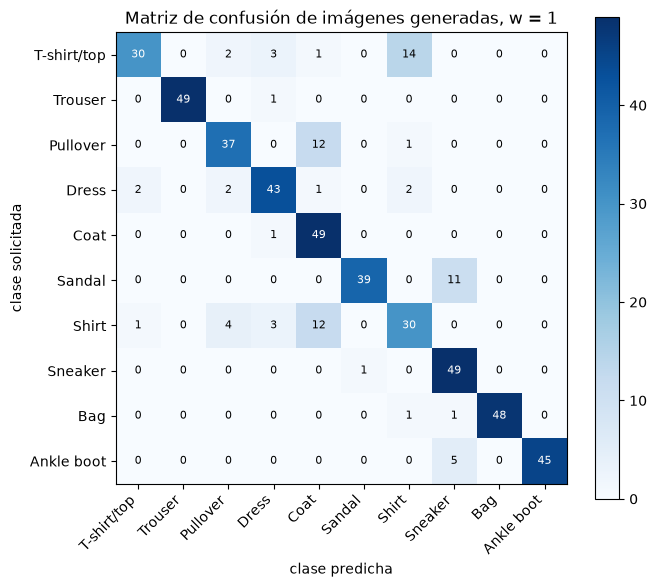


**Respuesta 3.5(a).** La fidelidad cambia de 0.838 con $w=1$ a 0.976 con $w=3$ y 0.980 con $w=7$. La diversidad pasa de 14.927 a 13.109 y 12.081, respectivamente. La clase que más diversidad pierde es **Coat**: baja de 16.710 a 9.887. En la figura se observa que con guía alta las muestras repiten una forma dominante; la condición ayuda al clasificador, pero reduce las variaciones dentro de la clase.

**Respuesta 3.5(b).** El par con más confusión acumulada es **T-shirt/top / Shirt**, con 15 errores entre ambas direcciones. En la cuadrícula de $w=1$, las filas de T-shirt/top y Shirt incluyen prendas con mangas y siluetas muy parecidas. Esa ambigüedad corresponde en parte al modelo generativo. Además, estas clases comparten siluetas en Fashion-MNIST y el clasificador real tiene una exactitud de 88.26%, no 100%; por eso no conviene atribuir toda la confusión a un solo componente.

**Respuesta 3.5(d).** La pérdida más alta aparece en el intervalo **1-100** (0.2120) y la más baja en **901-1000** (0.0001). En SNR muy bajo, $x_t$ se parece al mismo ruido que se intenta predecir y el error baja. En SNR alto, la imagen domina y separar el ruido pequeño resulta más difícil. El patrón se compara directamente con los regímenes contados en la Task 2.5(b).


In [25]:
# Matriz de confusión para w=1. Las filas son clases solicitadas y las columnas,
# clases predichas por el clasificador.
pred_w1 = predictions_by_w[1]
cm_w1 = torch.bincount(requested_classes * 10 + pred_w1, minlength=100).reshape(10, 10)
pair_scores = cm_w1 + cm_w1.T
pair_scores.fill_diagonal_(0)
pair_flat = int(pair_scores.argmax())
conf_a, conf_b = divmod(pair_flat, 10)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_w1.numpy(), cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("clase predicha"); ax.set_ylabel("clase solicitada")
ax.set_title("Matriz de confusión de imágenes generadas, w = 1")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm_w1[i, j]), ha="center", va="center", fontsize=8,
                color="white" if cm_w1[i, j] > cm_w1.max() / 2 else "black")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

fid = {row["w"]: row["fidelidad global"] for row in metric_rows}
div = {row["w"]: row["diversidad global"] for row in metric_rows}
loss_max_i = int(np.argmax(val_interval_loss))
loss_min_i = int(np.argmin(val_interval_loss))

analysis_35 = fr'''
**Respuesta 3.5(a).** La fidelidad cambia de {fid[1]:.3f} con $w=1$ a {fid[3]:.3f} con $w=3$ y {fid[7]:.3f} con $w=7$. La diversidad pasa de {div[1]:.3f} a {div[3]:.3f} y {div[7]:.3f}, respectivamente. La clase que más diversidad pierde es **{CLASSES[most_affected_class]}**: baja de {diversity_by_w[1][most_affected_class]:.3f} a {diversity_by_w[7][most_affected_class]:.3f}. En la figura se observa que con guía alta las muestras repiten una forma dominante; la condición ayuda al clasificador, pero reduce las variaciones dentro de la clase.

**Respuesta 3.5(b).** El par con más confusión acumulada es **{CLASSES[conf_a]} / {CLASSES[conf_b]}**, con {int(cm_w1[conf_a, conf_b] + cm_w1[conf_b, conf_a])} errores entre ambas direcciones. En la cuadrícula de $w=1$, las filas de T-shirt/top y Shirt incluyen prendas con mangas y siluetas muy parecidas. Esa ambigüedad corresponde en parte al modelo generativo. Además, estas clases comparten siluetas en Fashion-MNIST y el clasificador real tiene una exactitud de {100*classifier_val_accuracy:.2f}%, no 100%; por eso no conviene atribuir toda la confusión a un solo componente.

**Respuesta 3.5(d).** La pérdida más alta aparece en el intervalo **{interval_labels[loss_max_i]}** ({val_interval_loss[loss_max_i]:.4f}) y la más baja en **{interval_labels[loss_min_i]}** ({val_interval_loss[loss_min_i]:.4f}). En SNR muy bajo, $x_t$ se parece al mismo ruido que se intenta predecir y el error baja. En SNR alto, la imagen domina y separar el ruido pequeño resulta más difícil. El patrón se compara directamente con los regímenes contados en la Task 2.5(b).
'''
display(Markdown(analysis_35))

### (c) Demostración de la guía sin clasificador

El score condicional se puede escribir con Bayes:

$$
\nabla_x\log p_t(x\mid c)
=\nabla_x\log p_t(x)+\nabla_x\log p_t(c\mid x).
$$

Como $s_\theta\approx-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$, la combinación de predicciones de ruido produce la misma combinación de scores:

$$
\begin{aligned}
\tilde s
&=s(x,t,\varnothing)+w\,[s(x,t,c)-s(x,t,\varnothing)]\\
&=\nabla_x\log p_t(x)+w\,\nabla_x\log p_t(c\mid x)\\
&=\nabla_x\log\left[p_t(x)\,p_t(c\mid x)^w\right].
\end{aligned}
$$

Por tanto, la distribución guiada cumple

$$\tilde p_t(x\mid c)\propto p_t(x)\,p_t(c\mid x)^w.$$

Al crecer $w$, la densidad se concentra en imágenes a las que el modelo asigna alta probabilidad de pertenecer a la clase solicitada. Esto aumenta la fidelidad cuando la guía funciona, pero descarta regiones menos típicas de la clase y reduce la diversidad, como se explica en S14.

# Task 4 - Comparaciones y pass@k

## Task 4.1 - VAE frente a difusión

In [26]:
# Nitidez sobre 500 imágenes de cada origen, todas en una escala equivalente.
set_seed(SEED + 20)
with torch.no_grad():
    vae_500 = model1.decode(torch.randn(500, latent_dim, device=device)).cpu()
sharp_real_500 = sharpness(X_va_f[:500].cpu())
sharp_vae_500 = sharpness(vae_500)
sharp_diff_500 = sharpness(((samples_w1 + 1) / 2).flatten(1))

# El tiempo del VAE es muy corto; se usa la mediana de 20 mediciones de un lote
# de 100 para reducir el efecto del reloj. La difusión se mide con 100 imágenes.
vae_times = []
model1.eval()
for rep in range(20):
    z = torch.randn(100, latent_dim, device=device)
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        _ = model1.decode(z).cpu()
    if device.type == "cuda": torch.cuda.synchronize()
    vae_times.append(time.perf_counter() - start)
vae_time_100 = float(np.median(vae_times))

_, diffusion_time_100 = ancestral_sample(
    diffusion_model, torch.arange(10).repeat_interleave(10), w=1.0, seed=SEED + 30
)
time_ratio = diffusion_time_100 / vae_time_100

df_compare = pd.DataFrame({
    "origen": ["reales", "VAE beta=1", "difusión w=1"],
    "nitidez": [sharp_real_500, sharp_vae_500, sharp_diff_500],
})
display(df_compare.round(4))
print(f"VAE, 100 imágenes: {vae_time_100:.6f} s, 1 evaluación de decoder")
print(f"Difusión, 100 imágenes: {diffusion_time_100:.3f} s, {T} evaluaciones de U-Net")
print(f"Razón difusión/VAE: {time_ratio:.1f}x")

answer_41 = fr'''
**Respuesta 4.1.** La nitidez fue {sharp_real_500:.4f} para imágenes reales, {sharp_vae_500:.4f} para el VAE y {sharp_diff_500:.4f} para difusión. El VAE genera 100 imágenes en {vae_time_100:.6f} s con una evaluación del decoder. La difusión tarda {diffusion_time_100:.3f} s y necesita {T} evaluaciones de la U-Net, una por paso; en este equipo fue {time_ratio:.1f} veces más lenta.

Los resultados siguen el mapa de compensaciones de S14. El VAE entrena de forma estable y genera rápido, pero su decoder con pérdida cuadrática produce promedios suaves. La difusión también usa una regresión estable, evita el entrenamiento adversarial y recupera detalle gradualmente, a cambio de un muestreo mucho más lento. Para reducir ese costo se puede difundir en el espacio latente de un VAE, como en la diapositiva de difusión latente, y usar un muestreador que necesite menos pasos después de verificar que no degrade demasiado las imágenes.
'''
display(Markdown(answer_41))

,origen,nitidez
0,reales,0.0886
1,VAE beta=1,0.0499
2,difusión w=1,0.0736


VAE, 100 imágenes: 0.000888 s, 1 evaluación de decoder
Difusión, 100 imágenes: 12.853 s, 1000 evaluaciones de U-Net
Razón difusión/VAE: 14470.9x



**Respuesta 4.1.** La nitidez fue 0.0886 para imágenes reales, 0.0499 para el VAE y 0.0736 para difusión. El VAE genera 100 imágenes en 0.000888 s con una evaluación del decoder. La difusión tarda 12.853 s y necesita 1000 evaluaciones de la U-Net, una por paso; en este equipo fue 14470.9 veces más lenta.

Los resultados siguen el mapa de compensaciones de S14. El VAE entrena de forma estable y genera rápido, pero su decoder con pérdida cuadrática produce promedios suaves. La difusión también usa una regresión estable, evita el entrenamiento adversarial y recupera detalle gradualmente, a cambio de un muestreo mucho más lento. Para reducir ese costo se puede difundir en el espacio latente de un VAE, como en la diapositiva de difusión latente, y usar un muestreador que necesite menos pasos después de verificar que no degrade demasiado las imágenes.


## Task 4.2 - Estimador pass@k

La presentación S14 evalúa código por corrección funcional: una solución cuenta como correcta si pasa todas las pruebas. Para $n$ muestras y $c$ soluciones correctas se usa

$$\operatorname{pass@k}=1-\frac{\binom{n-c}{k}}{\binom nk}.$$

In [27]:
from math import comb

n = 20
problem_names = ["P1", "P2", "P3", "P4", "P5", "P6"]
correct_counts = [0, 2, 5, 9, 14, 20]


def pass_at_k(n, c, k):
    return 1.0 if n - c < k else 1.0 - comb(n - c, k) / comb(n, k)


pass_rows = []
for name, c in zip(problem_names, correct_counts):
    row = {"problema": name, "n": n, "c": c}
    for k in [1, 5, 10]:
        row[f"pass@{k}"] = pass_at_k(n, c, k)
    row["ingenuo@5"] = 1 - (1 - c / n) ** 5
    pass_rows.append(row)

df_pass = pd.DataFrame(pass_rows)
display(df_pass.round(6))
print("Promedios:", {f"pass@{k}": float(df_pass[f"pass@{k}"].mean()) for k in [1, 5, 10]})

p2_k5 = pass_at_k(20, 2, 5)
p2_min_k = next(k for k in range(1, 21) if pass_at_k(20, 2, k) > 0.9)

answer_42 = fr'''
**Respuesta 4.2(a).** La tabla contiene los valores por problema. Los promedios son pass@1 = {df_pass['pass@1'].mean():.6f}, pass@5 = {df_pass['pass@5'].mean():.6f} y pass@10 = {df_pass['pass@10'].mean():.6f}. Para P2 y $k=5$:

$$
1-\frac{{\binom{{18}}{{5}}}}{{\binom{{20}}{{5}}}}
=1-\frac{{8568}}{{15504}}
={p2_k5:.6f}.
$$

**Respuesta 4.2(b).** Para P2 hay 18 fallos y 2 aciertos. Al simplificar:

$$
\frac{{\binom{{18}}{{k}}}}{{\binom{{20}}{{k}}}}
=\frac{{(20-k)(19-k)}}{{20\cdot19}},
$$

por lo que $\operatorname{{pass@k}}=1-(20-k)(19-k)/380$. Con $k=13$ se obtiene $1-42/380=0.8895$; con $k=14$, $1-30/380=0.9211$. El menor valor que supera 0.9 es **$k={p2_min_k}$**.

**Respuesta 4.2(c).** El estimador ingenuo aparece en la última columna. Para $i\ge0$,

$$\frac{{n-c-i}}{{n-i}}\le\frac{{n-c}}{{n}},$$

así que la probabilidad de obtener $k$ fallos al muestrear sin reemplazo satisface

$$
\prod_{{i=0}}^{{k-1}}\frac{{n-c-i}}{{n-i}}
\le\left(\frac{{n-c}}{{n}}\right)^k.
$$

Al restar de uno, el estimador insesgado es mayor o igual que $1-(1-c/n)^k$. Si quedan menos de $k$ fallos, el estimador insesgado vale 1 porque cualquier subconjunto de tamaño $k$ contiene al menos un acierto.

**Respuesta 4.2(d).** P1 no se resuelve aunque se intente diez veces. P5 y P6 tienen pass@10 = 1 en esta muestra; P3 y P4 quedan muy cerca de 1. P2 llega a {df_pass.loc[1, 'pass@10']:.3f}, así que todavía falla aproximadamente una de cada cuatro veces. El promedio sube de {df_pass['pass@1'].mean():.3f} a {df_pass['pass@10'].mean():.3f}: el modelo suele producir al menos una solución útil cuando puede reintentar y verificar, aunque los reintentos no ayudan en problemas donde nunca genera una solución correcta, como P1.
'''
display(Markdown(answer_42))

,problema,n,c,pass@1,pass@5,pass@10,ingenuo@5
0,P1,20,0,0.00,0.000000,0.000000,0.000000
1,P2,20,2,0.10,0.447368,0.763158,0.409510
2,P3,20,5,0.25,0.806308,0.983746,0.762695
3,P4,20,9,0.45,0.970201,0.999940,0.949672
4,P5,20,14,0.70,0.999613,1.000000,0.997570
5,P6,20,20,1.00,1.000000,1.000000,1.000000


Promedios: {'pass@1': 0.4166666666666667, 'pass@5': 0.7039151186790505, 'pass@10': 0.7911407477970945}



**Respuesta 4.2(a).** La tabla contiene los valores por problema. Los promedios son pass@1 = 0.416667, pass@5 = 0.703915 y pass@10 = 0.791141. Para P2 y $k=5$:

$$
1-\frac{\binom{18}{5}}{\binom{20}{5}}
=1-\frac{8568}{15504}
=0.447368.
$$

**Respuesta 4.2(b).** Para P2 hay 18 fallos y 2 aciertos. Al simplificar:

$$
\frac{\binom{18}{k}}{\binom{20}{k}}
=\frac{(20-k)(19-k)}{20\cdot19},
$$

por lo que $\operatorname{pass@k}=1-(20-k)(19-k)/380$. Con $k=13$ se obtiene $1-42/380=0.8895$; con $k=14$, $1-30/380=0.9211$. El menor valor que supera 0.9 es **$k=14$**.

**Respuesta 4.2(c).** El estimador ingenuo aparece en la última columna. Para $i\ge0$,

$$\frac{n-c-i}{n-i}\le\frac{n-c}{n},$$

así que la probabilidad de obtener $k$ fallos al muestrear sin reemplazo satisface

$$
\prod_{i=0}^{k-1}\frac{n-c-i}{n-i}
\le\left(\frac{n-c}{n}\right)^k.
$$

Al restar de uno, el estimador insesgado es mayor o igual que $1-(1-c/n)^k$. Si quedan menos de $k$ fallos, el estimador insesgado vale 1 porque cualquier subconjunto de tamaño $k$ contiene al menos un acierto.

**Respuesta 4.2(d).** P1 no se resuelve aunque se intente diez veces. P5 y P6 tienen pass@10 = 1 en esta muestra; P3 y P4 quedan muy cerca de 1. P2 llega a 0.763, así que todavía falla aproximadamente una de cada cuatro veces. El promedio sube de 0.417 a 0.791: el modelo suele producir al menos una solución útil cuando puede reintentar y verificar, aunque los reintentos no ayudan en problemas donde nunca genera una solución correcta, como P1.
